In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df_original = pd.read_csv("/content/titanic.csv")
print("Dataset: Titanic Passenger Dataset")
print("File type: CSV")
print("Rows:", df_original.shape[0])
print("Columns:", df_original.shape[1])

Dataset: Titanic Passenger Dataset
File type: CSV
Rows: 891
Columns: 12


In [8]:
print("First five rows:")
display(df_original.head())
print("Last five rows:")
display(df_original.tail())
print("Shape:", df_original.shape)
print("Column names:", df_original.columns.tolist())
print("Dataset information:")
df_original.info()

First five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Last five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


Shape: (891, 12)
Column names: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [9]:
numeric_columns = df_original.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df_original.select_dtypes(include=["object", "category"]).columns.tolist()
print("Numerical columns:", numeric_columns)
print("Categorical columns:", categorical_columns)
print("Numerical summary statistics:")
display(df_original.describe().T)
for col in ["Sex", "Embarked", "Pclass"]:
    print(f"\nFrequency counts for {col}:")
    display(df_original[col].value_counts(dropna=False))

Numerical columns: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical columns: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']
Numerical summary statistics:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292



Frequency counts for Sex:


,count
Sex,
male,577
female,314



Frequency counts for Embarked:


,count
Embarked,
S,644
C,168
Q,77
NaN,2



Frequency counts for Pclass:


,count
Pclass,
3,491
1,216
2,184


In [10]:
missing_count = df_original.isnull().sum()
missing_percent = (missing_count / len(df_original) * 100).round(2)
missing_summary = pd.DataFrame({"Missing Values": missing_count, "Missing Percentage (%)": missing_percent})
display(missing_summary.sort_values("Missing Values", ascending=False))
print("Columns with no missing values:", missing_summary[missing_summary["Missing Values"] == 0].index.tolist())



,Missing Values,Missing Percentage (%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


Columns with no missing values: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'SibSp', 'Parch', 'Ticket', 'Fare']


In [11]:
df = df_original.copy()
df = df.drop(columns=["Cabin"])
age_median = df["Age"].median()
embarked_mode = df["Embarked"].mode()[0]
df["Age"] = df["Age"].fillna(age_median)
df["Embarked"] = df["Embarked"].fillna(embarked_mode)
print("Age median used:", age_median)
print("Embarked mode used:", embarked_mode)
print("Missing values after handling:")
display(df.isnull().sum().to_frame("Remaining Missing Values"))
print("Total remaining missing values:", df.isnull().sum().sum())

Age median used: 28.0
Embarked mode used: S
Missing values after handling:


,Remaining Missing Values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


Total remaining missing values: 0


In [12]:
duplicate_count = df.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)
if duplicate_count > 0:
    df = df.drop_duplicates().copy()
    print("Duplicate rows removed.")
else:
    print("No exact duplicate rows found; none removed.")
for col in ["Sex", "Embarked"]:
    df[col] = df[col].astype(str).str.strip()
df["Sex"] = df["Sex"].str.lower()
df["Embarked"] = df["Embarked"].str.upper()
print("Sex categories:", sorted(df["Sex"].unique()))
print("Embarked categories:", sorted(df["Embarked"].unique()))
print("Shape after checks:", df.shape)

Exact duplicate rows: 0
No exact duplicate rows found; none removed.
Sex categories: ['female', 'male']
Embarked categories: ['C', 'Q', 'S']
Shape after checks: (891, 11)


In [13]:
print("Numerical summary:")
display(df.describe().T)
print("Passenger counts by sex:")
display(df["Sex"].value_counts())
print("Survival counts (0 = No, 1 = Yes):")
display(df["Survived"].value_counts())

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,891.0,29.361582,13.019697,0.42,22.0000,28.0000,35.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


Passenger counts by sex:


,count
Sex,
male,577
female,314


Survival counts (0 = No, 1 = Yes):


,count
Survived,
0,549
1,342


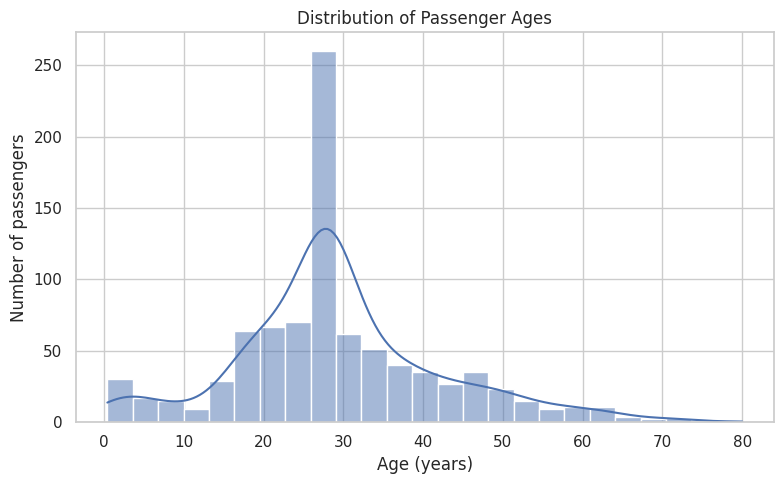

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", bins=25, kde=True)
plt.title("Distribution of Passenger Ages")
plt.xlabel("Age (years)")
plt.ylabel("Number of passengers")
plt.tight_layout()
plt.show()

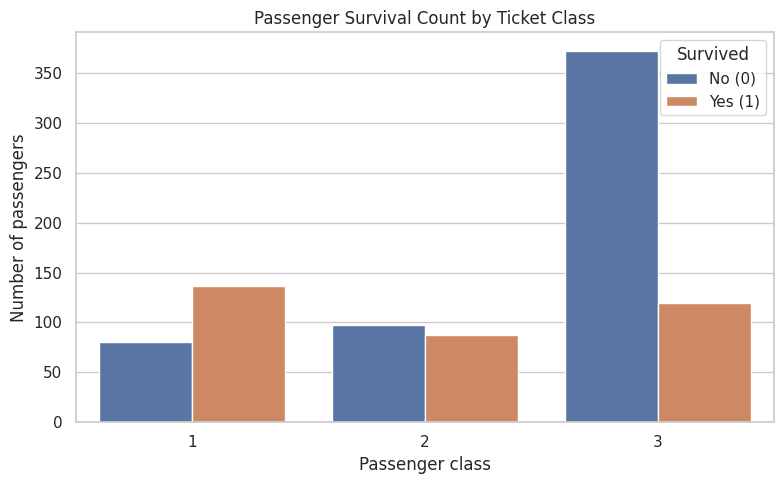

In [15]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Pclass", hue="Survived")
plt.title("Passenger Survival Count by Ticket Class")
plt.xlabel("Passenger class")
plt.ylabel("Number of passengers")
plt.legend(title="Survived", labels=["No (0)", "Yes (1)"])
plt.tight_layout()
plt.show()

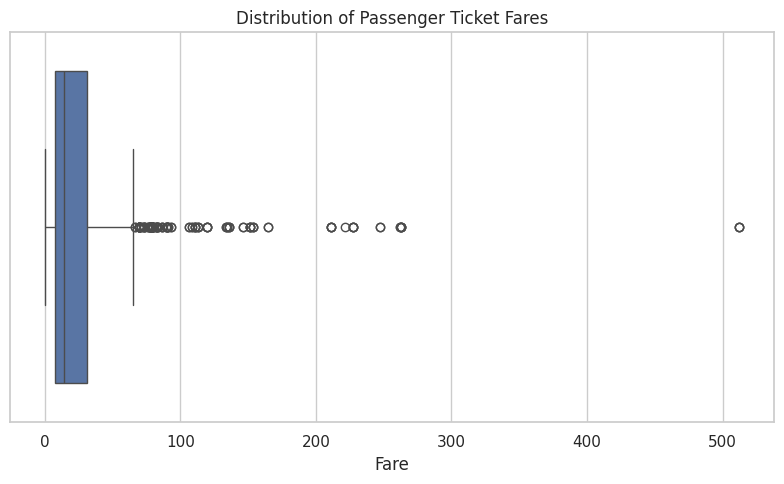

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Fare")
plt.title("Distribution of Passenger Ticket Fares")
plt.xlabel("Fare")
plt.tight_layout()
plt.show()

In [17]:
columns_to_drop = ["PassengerId", "Name", "Ticket"]
prepared = df.drop(columns=columns_to_drop).copy()
prepared["Pclass"] = prepared["Pclass"].astype(str)
categorical_to_encode = ["Sex", "Embarked", "Pclass"]
print("Categorical columns to encode:", categorical_to_encode)
print("Before encoding:")
display(prepared[categorical_to_encode].head())
prepared = pd.get_dummies(prepared, columns=categorical_to_encode, drop_first=False, dtype=int)
print("After encoding:")
display(prepared.head())
print("Encoded columns:", prepared.columns.tolist())

Categorical columns to encode: ['Sex', 'Embarked', 'Pclass']
Before encoding:


,Sex,Embarked,Pclass
0,male,S,3
1,female,C,1
2,female,S,3
3,female,S,1
4,male,S,3


After encoding:


,Survived,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
0,0,22.0,1,0,7.2500,0,1,0,0,1,0,0,1
1,1,38.0,1,0,71.2833,1,0,1,0,0,1,0,0
2,1,26.0,0,0,7.9250,1,0,0,0,1,0,0,1
3,1,35.0,1,0,53.1000,1,0,0,0,1,1,0,0
4,0,35.0,0,0,8.0500,0,1,0,0,1,0,0,1


Encoded columns: ['Survived', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Pclass_1', 'Pclass_2', 'Pclass_3']


In [18]:
numerical_features_to_scale = ["Age", "Fare", "SibSp", "Parch"]
scaler = StandardScaler()
prepared[numerical_features_to_scale] = scaler.fit_transform(prepared[numerical_features_to_scale])
print("Scaling method: StandardScaler")
print("Features scaled:", numerical_features_to_scale)
display(prepared[numerical_features_to_scale].agg(["mean", "std", "min", "max"]).T.round(3))
print("Survived target values (not scaled):", sorted(prepared["Survived"].unique()))

Scaling method: StandardScaler
Features scaled: ['Age', 'Fare', 'SibSp', 'Parch']


,mean,std,min,max
Age,0.0,1.001,-2.224,3.892
Fare,0.0,1.001,-0.648,9.667
SibSp,0.0,1.001,-0.475,6.784
Parch,0.0,1.001,-0.474,6.974


Survived target values (not scaled): [np.int64(0), np.int64(1)]


In [19]:
print("Final prepared dataset shape:", prepared.shape)
print("Total missing values:", prepared.isnull().sum().sum())
print("Duplicate rows:", prepared.duplicated().sum())
print("Sample of prepared data:")
display(prepared.head())
output_file = "titanic_prepared.csv"
prepared.to_csv(output_file, index=False)
print("Saved file:", output_file)

Final prepared dataset shape: (891, 13)
Total missing values: 0
Duplicate rows: 116
Sample of prepared data:


,Survived,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Pclass_1,Pclass_2,Pclass_3
0,0,-0.565736,0.432793,-0.473674,-0.502445,0,1,0,0,1,0,0,1
1,1,0.663861,0.432793,-0.473674,0.786845,1,0,1,0,0,1,0,0
2,1,-0.258337,-0.474545,-0.473674,-0.488854,1,0,0,0,1,0,0,1
3,1,0.433312,0.432793,-0.473674,0.420730,1,0,0,0,1,1,0,0
4,0,0.433312,-0.474545,-0.473674,-0.486337,0,1,0,0,1,0,0,1


Saved file: titanic_prepared.csv


In [20]:
# Download the prepared CSV file to your computer (Google Colab only)
from google.colab import files
files.download("titanic_prepared.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>